# Análise Exploratória dos Dados (EDA)

## Objetivo

Investigar a estrutura, a qualidade e os padrões dos dados de campanhas
publicitárias em vídeo, buscando identificar fatores associados ao
desempenho dos criativos.

## 1. Perfil geral dos dados
### 1.1 Carregamento e inspeção inicial

In [1]:
# Importação de bibliotecas
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd

In [2]:
dados = pd.read_csv('../data/klike_challenge_dataset.csv')
dados.head(5)

,campaign_id,date,platform,category,objective,target_audience_age,is_retargeting,video_duration_s,format,has_subtitle,...,clicks,ctr,cpc,spend,conversions,revenue,roas,avg_watch_time_s,engagement_rate,klike_score
0,KLK-0001,2024-01-01,Meta,Branding,awareness,18-24,False,NaN,vertical,True,...,5882,0.0390,0.82,4823.24,48,0.00,0.00,3.9,0.0446,63.6
1,KLK-0002,2024-03-22,LinkedIn,App Install,traffic,25-34,False,NaN,horizontal,True,...,493,0.0664,3.54,1745.22,34,NaN,0.16,6.4,0.0217,70.0
2,KLK-0003,2024-05-04,TikTok,SaaS,traffic,25-34,False,8.0,vertical,True,...,15069,0.0780,0.38,5726.22,492,51053.44,8.92,8.0,0.1000,99.1
3,KLK-0004,2024-12-27,TikTok,Lead Gen,engagement,25-34,False,27.0,quadrado,False,...,601,0.0925,0.71,426.71,19,1113.78,2.61,20.3,0.0414,74.9
4,KLK-0005,2024-07-10,Meta,Branding,engagement,25-34,False,34.0,vertical,True,...,2355,0.0369,0.38,894.90,13,0.00,0.00,34.0,0.0184,77.9


In [3]:
print(f"Tamanho do dataframe: {dados.shape}")
print(dados.info())

Tamanho do dataframe: (500, 26)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   campaign_id          500 non-null    str    
 1   date                 500 non-null    str    
 2   platform             500 non-null    str    
 3   category             500 non-null    str    
 4   objective            500 non-null    str    
 5   target_audience_age  500 non-null    str    
 6   is_retargeting       500 non-null    bool   
 7   video_duration_s     461 non-null    float64
 8   format               500 non-null    str    
 9   has_subtitle         454 non-null    object 
 10  has_cta              500 non-null    bool   
 11  has_hook             500 non-null    bool   
 12  has_face             500 non-null    bool   
 13  text_density         500 non-null    str    
 14  music_voice_ratio    462 non-null    float64
 15  impressions        

### 1.2 Primeiras observações
A base de dados fornecida é diversa, com diferentes tipos de variáveis e tem tamanho 500 linhas x 26 colunas. A variável target é a `klike_score`. A base possui alguns dados faltantes nas seguinte colunas: `video_duration_s`, `has_subtitle`, `music_voice_ratio`, `cpc`, `revenue`, `avg_watch_time_s` e `engagement_rate`. 

### 1.3 Tipos de variáveis

In [4]:
# Alterando variáveis para categóricas
categoricas = ['platform', 'category', 'objective', 'target_audience_age', 'is_retargeting', 'format', 'has_subtitle', 'has_cta', 
               'has_hook', 'has_face', 'text_density']
numericas = ['video_duration_s', 'music_voice_ratio', 'impressions', 'clicks', 'ctr', 'cpc', 'spend', 'conversions', 'revenue', 'roas', 
             'avg_watch_time_s', 'engagement_rate']

dados[categoricas] = dados[categoricas].astype('category')

# Lidando com as categóricas ordinais
dados.text_density = pd.Categorical(dados.text_density, categories=['low', 'medium', 'high'], ordered=True)
dados.target_audience_age = pd.Categorical(dados.target_audience_age, categories=['18-24', '25-34', '35-44', '45+'], ordered=True)

print(dados[categoricas].dtypes)

platform               category
category               category
objective              category
target_audience_age    category
is_retargeting         category
format                 category
has_subtitle           category
has_cta                category
has_hook               category
has_face               category
text_density           category
dtype: object


In [5]:
dados.platform.value_counts(normalize=True)

platform
Meta        0.482
TikTok      0.352
LinkedIn    0.166
Name: proportion, dtype: float64

In [6]:
dados.describe()

,video_duration_s,music_voice_ratio,impressions,clicks,ctr,cpc,spend,conversions,revenue,roas,avg_watch_time_s,engagement_rate,klike_score
count,461.000000,462.000000,5.000000e+02,500.000000,500.000000,472.000000,500.000000,500.0000,475.000000,500.000000,473.000000,468.000000,500.0000
mean,19.392625,0.399848,1.537385e+05,3594.104000,0.070968,1.112903,4213.151620,131.3520,6367.936863,2.499000,10.664271,0.027952,60.1568
std,13.529351,0.202674,1.171736e+06,7018.212512,0.045302,1.955625,11573.975576,314.5654,19267.180696,3.592365,10.533275,0.023057,15.5891
min,5.000000,0.020000,1.000000e+03,4.000000,0.002200,0.050000,2.960000,0.0000,0.000000,0.000000,0.400000,0.001000,10.4000
25%,11.000000,0.230000,9.986000e+03,461.750000,0.033200,0.530000,313.452500,10.0000,262.175000,0.430000,4.700000,0.011100,49.7750
50%,16.000000,0.385000,2.324100e+04,1351.000000,0.062750,0.710000,1031.000000,34.5000,1201.050000,1.490000,7.700000,0.021400,60.5500
75%,25.000000,0.550000,5.517275e+04,3583.250000,0.104800,1.020000,2867.952500,111.0000,4189.025000,3.250000,13.900000,0.038800,71.9250
max,115.000000,0.920000,1.405276e+07,72545.000000,0.150000,26.050000,121226.100000,3666.0000,241597.290000,39.920000,108.000000,0.100000,99.1000


### 1.4 Valores ausentes e duplicatas

In [7]:
print((dados.isna().mean()*100).round(2))

campaign_id            0.0
date                   0.0
platform               0.0
category               0.0
objective              0.0
target_audience_age    0.0
is_retargeting         0.0
video_duration_s       7.8
format                 0.0
has_subtitle           9.2
has_cta                0.0
has_hook               0.0
has_face               0.0
text_density           0.0
music_voice_ratio      7.6
impressions            0.0
clicks                 0.0
ctr                    0.0
cpc                    5.6
spend                  0.0
conversions            0.0
revenue                5.0
roas                   0.0
avg_watch_time_s       5.4
engagement_rate        6.4
klike_score            0.0
dtype: float64


In [8]:
dados.duplicated().sum()

np.int64(0)

**Conclusões:** Considerando o tamanho reduzido da base e a diversidade das campanhas, optei por preservar os registros originais durante a análise exploratória. Os valores ausentes foram identificados e quantificados, mas não foram imputados nesta etapa, pois o objetivo é compreender os padrões dos dados sem introduzir alterações desnecessárias. Os tratamentos exigidos pelos algoritmos serão realizados posteriormente, durante a modelagem, de forma a evitar vazamento de informações.

### 1.5 Distribuições e outliers

In [9]:
dados[numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
video_duration_s,461.0,19.392625,1.352935e+01,5.0000,11.0000,16.00000,25.0000,115.00
music_voice_ratio,462.0,0.399848,2.026735e-01,0.0200,0.2300,0.38500,0.5500,0.92
impressions,500.0,153738.524000,1.171736e+06,1000.0000,9986.0000,23241.00000,55172.7500,14052761.00
clicks,500.0,3594.104000,7.018213e+03,4.0000,461.7500,1351.00000,3583.2500,72545.00
ctr,500.0,0.070968,4.530216e-02,0.0022,0.0332,0.06275,0.1048,0.15
cpc,472.0,1.112903,1.955625e+00,0.0500,0.5300,0.71000,1.0200,26.05
spend,500.0,4213.151620,1.157398e+04,2.9600,313.4525,1031.00000,2867.9525,121226.10
conversions,500.0,131.352000,3.145654e+02,0.0000,10.0000,34.50000,111.0000,3666.00
revenue,475.0,6367.936863,1.926718e+04,0.0000,262.1750,1201.05000,4189.0250,241597.29
roas,500.0,2.499000,3.592365e+00,0.0000,0.4300,1.49000,3.2500,39.92


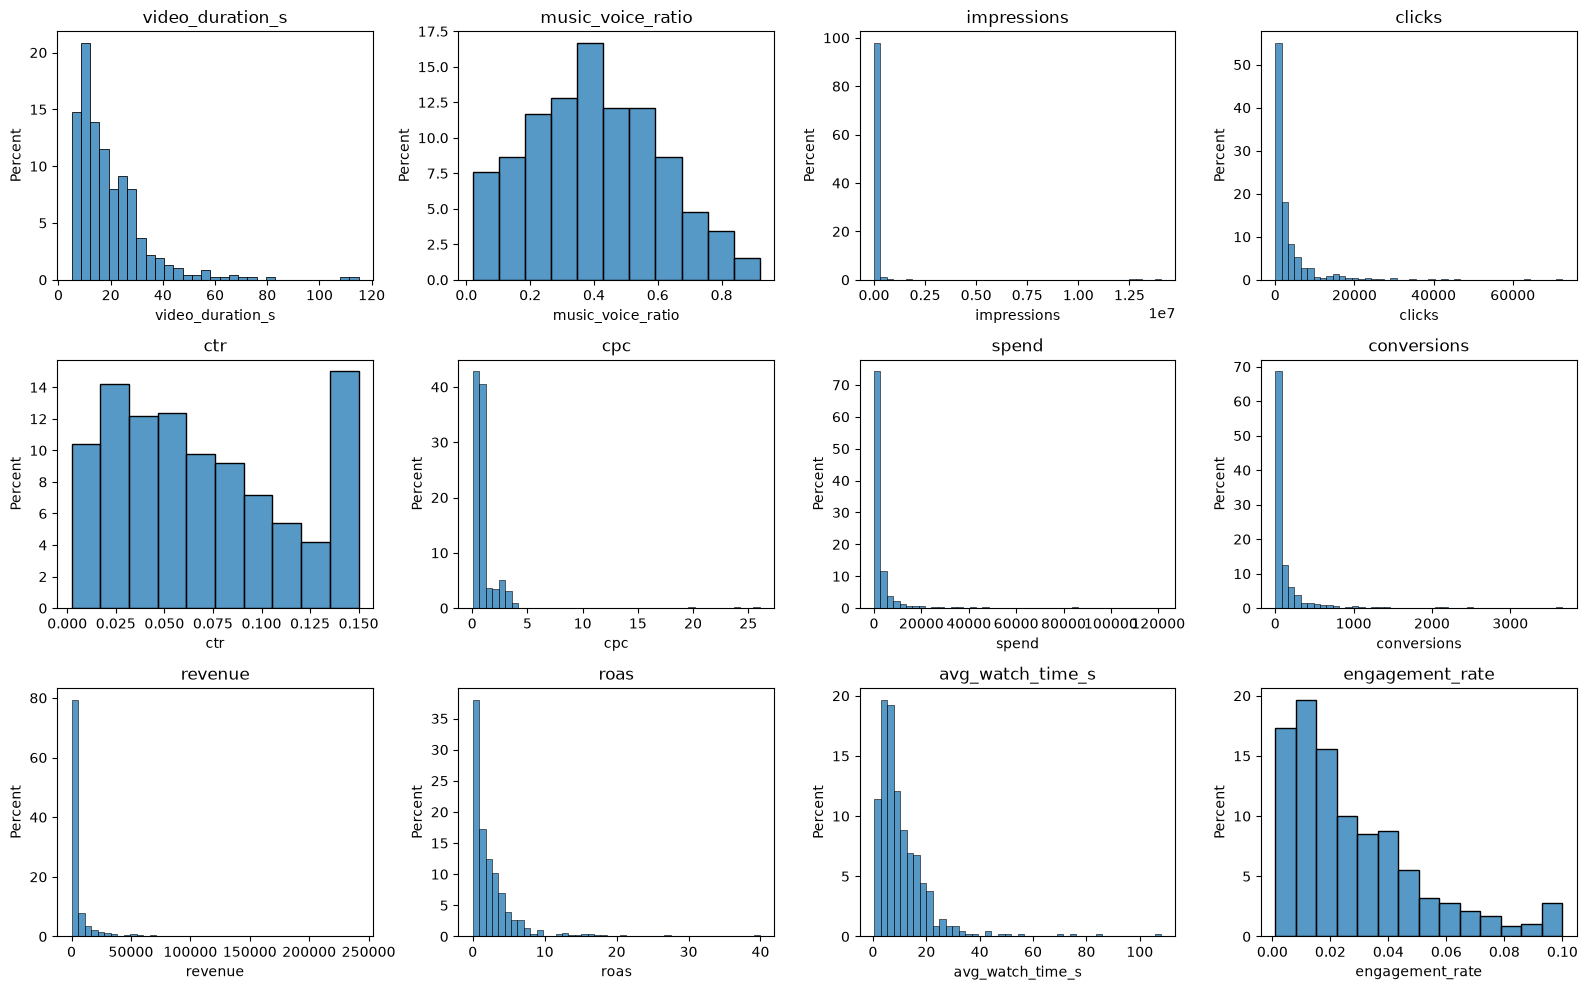

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for ax, coluna in zip(axes.flatten(), numericas):
    sns.histplot(data=dados, x=coluna, stat='percent', ax=ax)
    ax.set_title(coluna)

plt.tight_layout()
plt.show()

In [11]:
dados[numericas].skew().sort_values(ascending=False)

impressions          10.999062
cpc                   9.925326
revenue               8.343113
conversions           6.034078
spend                 5.943992
clicks                5.168734
roas                  4.403622
avg_watch_time_s      4.014319
video_duration_s      2.555327
engagement_rate       1.307332
ctr                   0.434883
music_voice_ratio     0.245551
dtype: float64

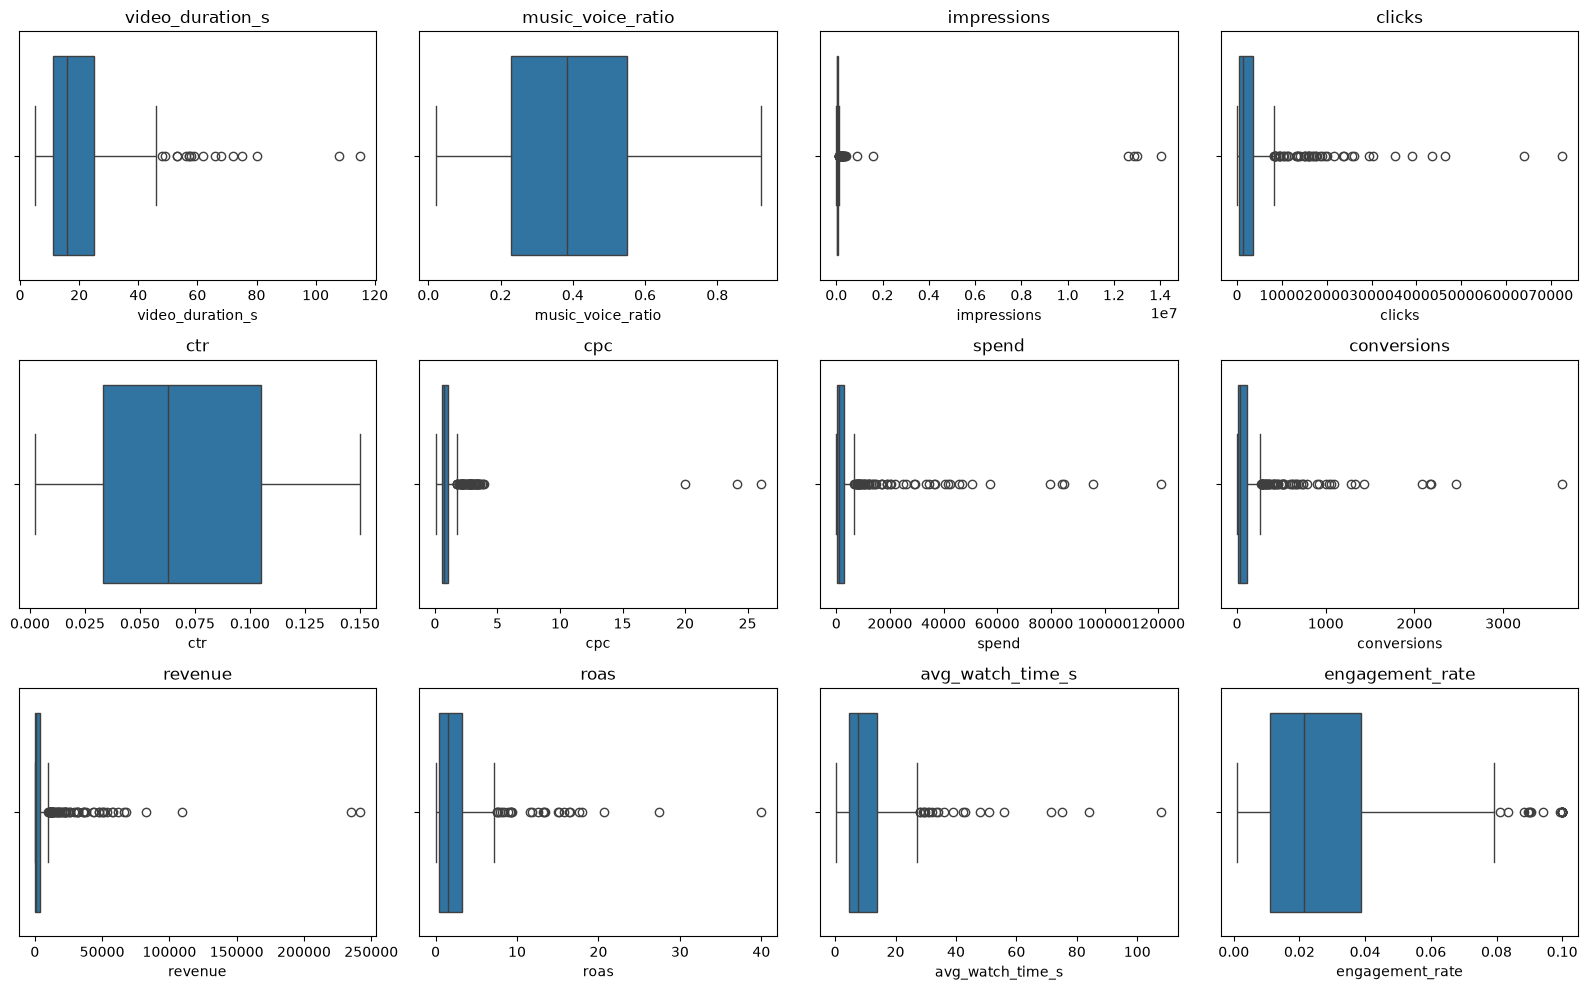

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for ax, coluna in zip(axes.flatten(), numericas):
    sns.boxplot(data=dados, x=coluna, ax=ax)
    ax.set_title(coluna)

plt.tight_layout()
plt.show()

#### Investigação de valores extremos

Para avaliar a plausibilidade dos outliers identificados, foram examinadas as cinco campanhas com maiores valores de CPC e ROAS, comparando essas métricas com as variáveis utilizadas em seus respectivos cálculos.

A análise identificou inconsistências nos valores de CPC das três primeiras campanhas apresentadas, uma vez que não correspondem à relação esperada entre investimento (`spend`) e número de cliques (`clicks`).

Em contrapartida, os valores extremos de ROAS apresentados são compatíveis, considerando arredondamentos, com a relação entre receita (`revenue`) e investimento (`spend`). Portanto, embora elevados, não constituem necessariamente erros de registro.

In [13]:
dados.nlargest(5, 'cpc')[['campaign_id', 'platform', 'clicks', 'spend', 'cpc']]

,campaign_id,platform,clicks,spend,cpc
415,KLK-0416,Meta,1538,1138.12,26.05
239,KLK-0240,Meta,2825,2768.50,24.17
99,KLK-0100,Meta,951,370.89,20.00
485,KLK-0486,LinkedIn,941,3707.54,3.94
441,KLK-0442,LinkedIn,149,567.69,3.81


In [14]:
dados.nlargest(5, 'roas')[['campaign_id', 'platform', 'revenue', 'spend', 'roas']]

,campaign_id,platform,revenue,spend,roas
7,KLK-0008,LinkedIn,2255.20,56.50,39.92
345,KLK-0346,TikTok,234866.62,8566.36,27.42
289,KLK-0290,TikTok,8676.32,418.84,20.72
283,KLK-0284,Meta,1447.50,80.52,17.98
19,KLK-0020,Meta,22374.02,1267.84,17.65


### 1.6 Conclusões

**Distribuições e outliers:** A maioria das variáveis numéricas apresenta assimetria positiva, especialmente métricas de alcance, investimento e retorno. Os boxplots indicam a presença de valores extremos, que não necessariamente representam erros, dada a diversidade de campanhas.

**Valores ausentes:** Foram identificados valores ausentes em 7 das 26 variáveis (entre 5% e 9,2%), sem ausência na variável-alvo `klike_score`. Não foram encontradas linhas completamente duplicadas.

**Tratamento:** Optou-se por preservar os registros nesta etapa, considerando o tamanho da base (500 campanhas) e a possibilidade de os valores extremos representarem observações legítimas. Futuramente, os valores ausentes poderão ser tratados por imputação adequada ao tipo de variável, enquanto inconsistências pontuais, como as observadas no `cpc`, deverão ser investigadas antes de possíveis correções. O pré-processamento necessário será realizado na etapa de modelagem.

## 2. Atributos dos criativos
### 2.1 Atributos categóricos e métricas de performance
Nesta etapa, foram comparadas as medianas das métricas de performance entre as diferentes categorias dos atributos dos criativos. A utilização da mediana busca reduzir a influência dos valores extremos identificados anteriormente, permitindo uma comparação do desempenho típico dos grupos.

A análise considera diferentes dimensões de performance, incluindo atração de cliques, engajamento, conversões, receita e eficiência financeira.

In [15]:
criativos = ['format', 'has_subtitle', 'has_cta', 'has_hook', 'has_face', 'text_density']
metricas = ['ctr', 'cpc', 'roas', 'conversions', 'revenue', 'engagement_rate', 'avg_watch_time_s']

In [16]:
for atributo in criativos:
    print(f'\n*********** {atributo} *************')
    display(dados.groupby(atributo, observed=True)[metricas].median())


*********** format *************


,ctr,cpc,roas,conversions,revenue,engagement_rate,avg_watch_time_s
format,,,,,,,
horizontal,0.0664,1.040,0.910,34.0,1373.550,0.0160,10.6
quadrado,0.0670,0.785,1.555,40.0,1285.335,0.0177,8.7
vertical,0.0565,0.590,1.840,31.0,1154.280,0.0269,6.5



*********** has_subtitle *************


,ctr,cpc,roas,conversions,revenue,engagement_rate,avg_watch_time_s
has_subtitle,,,,,,,
False,0.0592,0.71,1.60,33.0,1299.72,0.0209,7.0
True,0.0679,0.71,1.49,36.0,1201.05,0.0214,7.8



*********** has_cta *************


...

,ctr,cpc,roas,conversions,revenue,engagement_rate,avg_watch_time_s
has_hook,,,,,,,
False,0.04725,0.70,1.61,30.0,1016.46,0.01710,6.3
True,0.07920,0.75,1.33,40.0,1443.92,0.02335,9.5



*********** has_face *************


,ctr,cpc,roas,conversions,revenue,engagement_rate,avg_watch_time_s
has_face,,,,,,,
False,0.0519,0.70,1.54,29.0,1162.54,0.01655,7.0
True,0.0710,0.72,1.39,42.0,1260.77,0.02560,8.4



*********** text_density *************


,ctr,cpc,roas,conversions,revenue,engagement_rate,avg_watch_time_s
text_density,,,,,,,
low,0.0673,0.74,1.63,38.0,1386.275,0.0208,8.2
medium,0.0653,0.70,1.43,35.5,1196.200,0.0223,7.6
high,0.0426,0.73,1.10,26.0,933.275,0.0181,6.7


**Principais observações:**

- A presença de hook e rosto humano está associada a maiores taxas de cliques, engajamento e conversões, mas não necessariamente a maior ROAS.
- Criativos com CTA apresentam resultados medianos superiores em conversões, receita e ROAS.
- A alta densidade de texto está associada a desempenho inferior em diversas métricas, especialmente CTR e ROAS.
- As diferenças entre métricas reforçam que uma característica associada a melhores resultados em determinada dimensão não necessariamente apresenta o mesmo comportamento nas demais.

Essas comparações são exploratórias e não permitem estabelecer relações causais. Além disso, é importante observar que receita e conversões variam conforme a escala das campanhas.

### 2.2 Comparação por objetivo de campanha

Para complementar a análise dos atributos categóricos, foi investigada a distribuição de `has_hook`, `has_face` e `text_density` entre os diferentes objetivos de campanha.

O objetivo é verificar se esses atributos estão distribuídos de maneira semelhante ou se existem diferenças que possam influenciar as associações observadas nas métricas de performance.

In [17]:
dados.groupby('objective', observed=True)[['ctr', 'roas']].median()

,ctr,roas
objective,,
app_install,0.0709,0.635
awareness,0.0497,0.000
conversions,0.0615,2.300
engagement,0.0673,0.860
traffic,0.0627,1.575


In [18]:
display(pd.crosstab(dados['objective'], dados['has_hook'], normalize='index').round(2))
print('------------------------------')
display(pd.crosstab(dados['objective'], dados['has_face'], normalize='index').round(2))
print('------------------------------')
display(pd.crosstab(dados['objective'], dados['text_density'], normalize='index').round(2))

has_hook,False,True
objective,,
app_install,0.48,0.52
awareness,0.52,0.48
conversions,0.51,0.49
engagement,0.42,0.58
traffic,0.49,0.51


------------------------------


has_face,False,True
objective,,
app_install,0.48,0.52
awareness,0.37,0.63
conversions,0.50,0.50
engagement,0.47,0.53
traffic,0.45,0.55


------------------------------


text_density,low,medium,high
objective,,,
app_install,0.35,0.50,0.15
awareness,0.28,0.47,0.25
conversions,0.38,0.45,0.18
engagement,0.41,0.44,0.15
traffic,0.35,0.47,0.19


**Conclusão:** Os atributos analisados apresentam distribuições relativamente semelhantes entre os objetivos de campanha, com algumas diferenças pontuais. Destacam-se a maior presença de hooks em campanhas de *engagement* (58%) e de rostos humanos em campanhas de *awareness* (63%).

Essas variações sugerem que o objetivo da campanha pode influenciar a composição dos criativos. Entretanto, as proporções observadas não são suficientes para explicar as diferenças de performance identificadas anteriormente, sendo necessário considerar outros fatores, como plataforma e categoria.

### 2.3 Correlação dos atributos numéricos

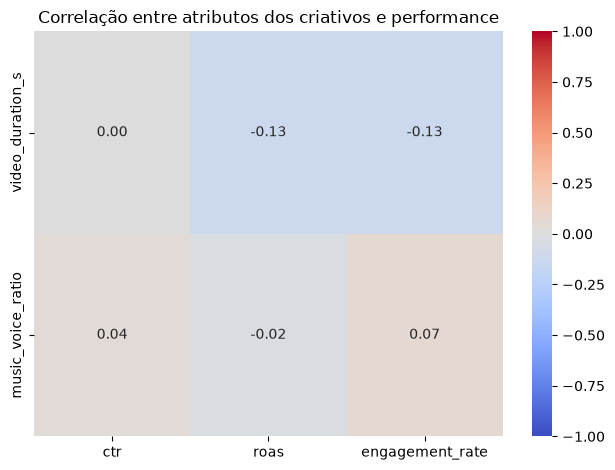

In [19]:
correlacoes = dados[['video_duration_s', 'music_voice_ratio', 'ctr', 'roas', 'engagement_rate']].corr(method='spearman')
sns.heatmap(correlacoes.loc[['video_duration_s', 'music_voice_ratio'], ['ctr', 'roas', 'engagement_rate']], annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlação entre atributos dos criativos e performance')
plt.tight_layout()
plt.show()

A análise de correlação de Spearman não identificou associações monotônicas fortes entre os atributos numéricos dos criativos e as métricas de performance. A duração dos vídeos apresentou correlações negativas fracas com ROAS e engajamento, enquanto a proporção entre música e voz apresentou associações próximas de zero.

### 2.4 Conclusões — Atributos dos criativos e performance

**Associações com a performance:** A presença de hook e rosto humano está associada a maiores medianas de CTR, engajamento, conversões e tempo de visualização, mas a menores valores medianos de ROAS. Já os criativos com CTA apresentam maiores medianas de conversões, receita e ROAS. A alta densidade de texto, por sua vez, está associada a menores valores de CTR, ROAS, conversões e receita.

**Atributos numéricos:** A correlação de Spearman não identificou associações monotônicas fortes entre duração do vídeo ou proporção música/voz e as métricas analisadas. A duração apresentou correlações negativas fracas com ROAS e engajamento.

**Influência dos objetivos de campanha:** A distribuição dos atributos é relativamente semelhante entre os objetivos, com algumas variações, como maior presença de rostos em campanhas de *awareness* (63%) e de hooks em campanhas de *engagement* (58%). Essas diferenças podem influenciar as comparações agregadas, mas não explicam, por si só, as diferenças de performance.

**Interpretação e limitações:** Os resultados indicam que características associadas a maior atenção e engajamento não necessariamente estão relacionadas a melhor retorno financeiro. Além disso, conversões e receita são métricas absolutas, influenciadas pela escala das campanhas. As associações observadas não estabelecem causalidade, reforçando a importância de considerar o contexto e o objetivo de cada campanha.

## 3. Comparação entre plataformas

Nesta etapa, serão investigadas as diferenças de desempenho entre Meta, TikTok e LinkedIn, buscando verificar se os padrões identificados anteriormente se mantêm nas diferentes plataformas.

### 3.1 Perfil geral das plataformas

Inicialmente, serão analisadas a distribuição das campanhas e as métricas gerais de desempenho de cada plataforma, considerando CTR, ROAS e taxa de engajamento.

In [20]:
dados['platform'].value_counts(normalize=True)

platform
Meta        0.482
TikTok      0.352
LinkedIn    0.166
Name: proportion, dtype: float64

In [21]:
dados.groupby('platform', observed=True)[['ctr', 'roas', 'engagement_rate']].agg(['mean', 'median'])

ctr              roas        engagement_rate         
              mean  median      mean median            mean   median
platform                                                            
LinkedIn  0.070841  0.0670  1.128434  0.530        0.021068  0.01720
Meta      0.072285  0.0646  2.176349  1.620        0.022422  0.01795
TikTok    0.069223  0.0562  3.587159  2.635        0.038649  0.03420

A comparação geral entre plataformas mostrou que o Meta apresenta maior CTR médio, enquanto o TikTok se destaca em ROAS médio e taxa de engajamento. Além disso, as médias de ROAS são superiores às medianas nas três plataformas, evidenciando a influência de campanhas com retornos elevados e reforçando a importância de considerar medidas robustas nas comparações.

### 3.2 Desempenho dos atributos por plataforma

In [22]:
atributos = ['has_hook', 'has_face', 'text_density']

for atributo in atributos:
    print(f'\n--------------- {atributo} -----------------')

    display(dados.groupby(['platform', atributo], observed=True)[['ctr', 'roas', 'engagement_rate']].median())


--------------- has_hook -----------------


ctr  roas  engagement_rate
platform has_hook                                
LinkedIn False     0.03910  0.53          0.01680
         True      0.08560  0.53          0.01760
Meta     False     0.04950  1.81          0.01450
         True      0.07795  1.32          0.02075
TikTok   False     0.04350  2.20          0.03095
         True      0.07800  2.99          0.03795


--------------- has_face -----------------


ctr   roas  engagement_rate
platform has_face                                 
LinkedIn False     0.04370  0.530          0.01605
         True      0.07065  0.530          0.01760
Meta     False     0.06335  1.610          0.01450
         True      0.06700  1.620          0.02235
TikTok   False     0.04535  2.665          0.02885
         True      0.07915  2.560          0.03890


--------------- text_density -----------------


ctr   roas  engagement_rate
platform text_density                                 
LinkedIn low           0.06670  0.405           0.0172
         medium        0.06870  0.580           0.0195
         high          0.06030  0.630           0.0142
Meta     low           0.06785  1.625           0.0165
         medium        0.07080  1.540           0.0203
         high          0.03710  1.655           0.0164
TikTok   low           0.06150  3.290           0.0430
         medium        0.05830  2.285           0.0317
         high          0.04260  2.300           0.0356

Para comparar os atributos dos criativos entre plataformas, foram utilizadas as **medianas** de CTR, ROAS e taxa de engajamento, devido à assimetria das distribuições e à presença de valores extremos, especialmente nas métricas financeiras.

**Principais observações:**

- **Presença de hook:** associada a CTR e engajamento medianos maiores nas três plataformas. Entretanto, o ROAS apresenta comportamentos distintos: aumenta no TikTok, diminui no Meta e permanece estável no LinkedIn.
- **Presença de rosto humano:** associada a CTR e engajamento medianos maiores em todas as plataformas, mas sem diferenças expressivas ou consistentes no ROAS.
- **Densidade de texto:** criativos com alta densidade apresentam CTR mediano inferior aos demais grupos nas três plataformas. Já o ROAS varia de maneira diferente conforme a plataforma.

**Interpretação:** Os resultados sugerem que determinadas características dos criativos apresentam associações relativamente consistentes com métricas de atenção e engajamento, mas não necessariamente com retorno financeiro. Isso reforça a importância de considerar a plataforma e a métrica de interesse na elaboração de recomendações.

As diferenças observadas são descritivas e não estabelecem relações causais.

### 3.3 Conclusões — Comparação entre plataformas

A análise identificou diferenças nos padrões de performance entre Meta, TikTok e LinkedIn. Embora a presença de hook e rosto humano esteja associada a maiores taxas de cliques e engajamento nas três plataformas, o comportamento do ROAS varia conforme o contexto.

O caso mais evidente é o hook: no TikTok, sua presença está associada a um ROAS mediano maior, enquanto no Meta ocorre o contrário e, no LinkedIn, não foi observada diferença.

Esses resultados indicam que **uma característica associada a melhor desempenho em determinada métrica ou plataforma não necessariamente apresenta o mesmo comportamento em outros contextos**. Portanto, recomendações de otimização devem considerar a plataforma e o objetivo da campanha, evitando generalizações a partir de resultados agregados.

## 4. Visualizações para o time de marketing

Nesta seção, foram selecionadas três visualizações
para comunicar os principais padrões identificados na EDA,
priorizando descobertas relevantes para a otimização
de criativos publicitários.

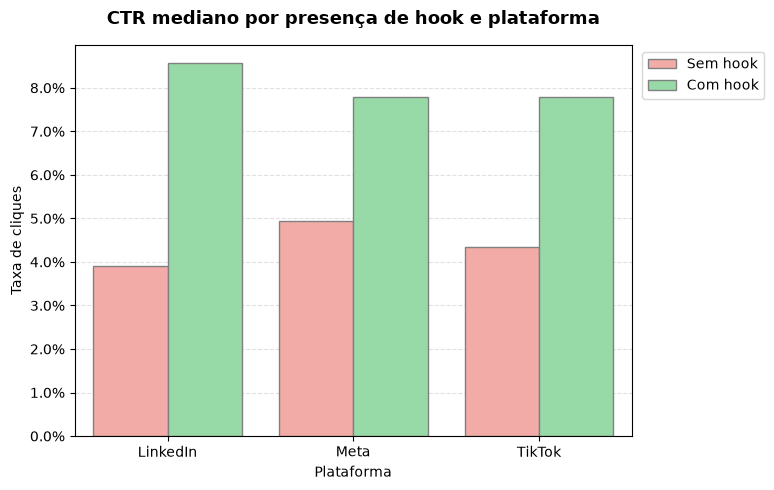

In [23]:
from matplotlib.ticker import PercentFormatter
cores = {False:'#ff9f9b', True:'#8de5a1'}
plt.figure(figsize=(8,5))
ax = sns.barplot(data=dados, x='platform', y='ctr', hue='has_hook', estimator='median', errorbar=None, palette=cores, edgecolor='grey')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
sns.move_legend(ax, loc='upper right', bbox_to_anchor=(1.25,1), title=None, labels=['Sem hook', 'Com hook'])
plt.title('CTR mediano por presença de hook e plataforma', fontsize=13, fontweight='bold', pad=15, loc='center')
plt.xlabel('Plataforma')
plt.ylabel('Taxa de cliques')
ax.set_axisbelow(True)
plt.grid(axis='y', color='lightgray', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('../images/CTR-hook-plataforma-1.png', dpi=300, bbox_inches='tight')
plt.show()

**Insight 1 — Presença de hook e CTR**

Campanhas com hook apresentam CTR mediano superior nas três plataformas, com destaque para o LinkedIn, onde a diferença entre os grupos é mais expressiva. Esse padrão sugere uma associação consistente entre a presença de hook e maiores taxas de cliques, embora não seja possível estabelecer causalidade.

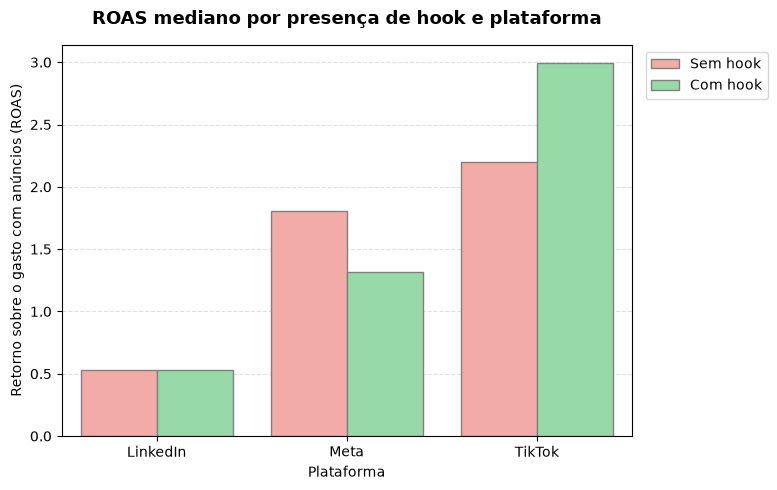

In [24]:
cores = {False:'#ff9f9b', True:'#8de5a1'}
plt.figure(figsize=(8,5))
ax = sns.barplot(data=dados, x='platform', y='roas', hue='has_hook', estimator='median', errorbar=None, palette=cores, edgecolor='grey')
sns.move_legend(ax, loc='upper right', bbox_to_anchor=(1.25,1), title=None, labels=['Sem hook', 'Com hook'])
plt.title('ROAS mediano por presença de hook e plataforma', fontsize=13, fontweight='bold', pad=15, loc='center')
plt.xlabel('Plataforma')
plt.ylabel('Retorno sobre o gasto com anúncios (ROAS)')
ax.set_axisbelow(True)
plt.grid(axis='y', color='lightgray', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('../images/ROAS-hook-plataforma-2.png', dpi=300, bbox_inches='tight')
plt.show()

**Insight 2 — Presença de hook e retorno financeiro**

Embora a presença de hook esteja associada a CTR mediano superior nas três plataformas, sua relação com o ROAS varia. No TikTok, campanhas com hook apresentam ROAS mediano aproximadamente 35,9% maior, enquanto no Meta apresentam valor 27,1% menor. No LinkedIn, não foi observada diferença entre os grupos.

Esses resultados reforçam que características associadas a mais cliques não necessariamente estão associadas a maior retorno financeiro e que recomendações devem considerar a plataforma e a métrica de interesse.

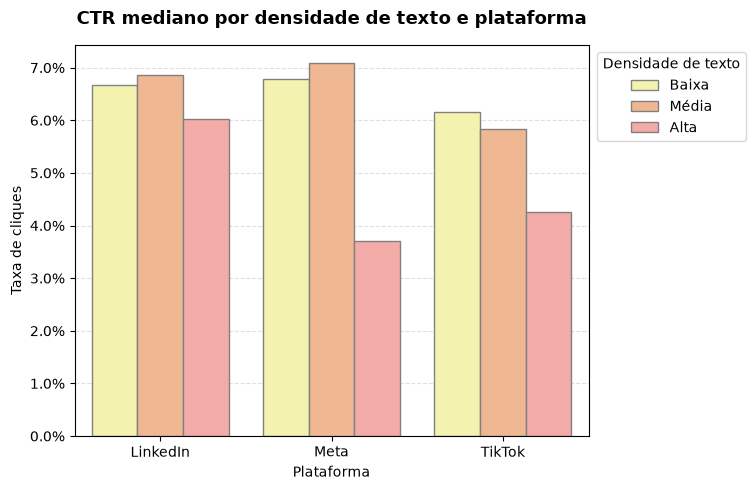

In [25]:
cores = {'low':'#fffea3', 'medium':'#ffb482', 'high':'#ff9f9b'}
plt.figure(figsize=(8,5))
ax = sns.barplot(data=dados, x='platform', y='ctr', hue='text_density', estimator='median', errorbar=None, palette=cores, edgecolor='grey')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
sns.move_legend(ax, loc='upper right', bbox_to_anchor=(1.32,1), title='Densidade de texto', labels=['Baixa', 'Média', 'Alta'])
plt.title('CTR mediano por densidade de texto e plataforma', fontsize=13, fontweight='bold', pad=15, loc='center')
plt.xlabel('Plataforma')
plt.ylabel('Taxa de cliques')
ax.set_axisbelow(True)
plt.grid(axis='y', color='lightgray', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('../images/CTR-texto-plataforma-3.png', dpi=300, bbox_inches='tight')
plt.show()

**Insight 3 — Densidade de texto e CTR**

Criativos com alta densidade de texto apresentam CTR mediano inferior aos demais grupos nas três plataformas, com destaque para o Meta, onde a diferença é mais expressiva. Entretanto, a densidade média supera ligeiramente a baixa no Meta e no LinkedIn, indicando que a relação entre quantidade de texto e desempenho não é necessariamente linear.

Esses resultados sugerem que a densidade de texto pode ser um atributo relevante para recomendações de otimização, considerando as particularidades de cada plataforma, sem estabelecer uma relação causal.